In [ ]:
from google.colab import files

uploaded = files.upload()

print("Uploaded files:")
print(list(uploaded.keys()))

Saving CMAPSSData.zip to CMAPSSData.zip
Uploaded files:
['CMAPSSData.zip']


In [ ]:
import os
import zipfile

filename = list(uploaded.keys())[0]

print("File:", filename)
print("Size:", os.path.getsize(filename), "bytes")
print("Is valid ZIP:", zipfile.is_zipfile(filename))

File: CMAPSSData.zip
Size: 12425978 bytes
Is valid ZIP: True


In [ ]:
import zipfile
import os

with zipfile.ZipFile(filename, "r") as zip_ref:
    zip_ref.extractall("CMAPSS")

print("Extracted successfully!")
print(os.listdir("CMAPSS"))

Extracted successfully!
['train_FD003.txt', 'RUL_FD002.txt', 'readme.txt', 'Damage Propagation Modeling.pdf', 'test_FD001.txt', 'RUL_FD001.txt', 'RUL_FD004.txt', 'train_FD002.txt', 'train_FD001.txt', 'test_FD002.txt', 'train_FD004.txt', 'test_FD004.txt', 'test_FD003.txt', 'RUL_FD003.txt']


In [ ]:
zip_path = "CMAPSSData.zip"

In [ ]:
import pandas as pd

# Column names for CMAPSS FD001
columns = (
    ["unit", "cycle"] +
    [f"op_setting_{i}" for i in range(1, 4)] +
    [f"sensor_{i}" for i in range(1, 22)]
)

# Load FD001 training data
train_df = pd.read_csv(
    "CMAPSS/train_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# Load FD001 test data
test_df = pd.read_csv(
    "CMAPSS/test_FD001.txt",
    sep=r"\s+",
    header=None,
    names=columns
)

# Load actual RUL values for test engines
rul_df = pd.read_csv(
    "CMAPSS/RUL_FD001.txt",
    sep=r"\s+",
    header=None,
    names=["RUL"]
)

print("Training data shape:", train_df.shape)
print("Testing data shape:", test_df.shape)
print("Test RUL shape:", rul_df.shape)

Training data shape: (20631, 26)
Testing data shape: (13096, 26)
Test RUL shape: (100, 1)


In [ ]:
train_df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [ ]:
# Calculate the maximum cycle reached by each engine
max_cycles = train_df.groupby("unit")["cycle"].max()

# Calculate Remaining Useful Life (RUL)
train_df["RUL"] = train_df.apply(
    lambda row: max_cycles[row["unit"]] - row["cycle"],
    axis=1
)

# Display the updated dataset
train_df.head()

,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191.0
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190.0
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189.0
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188.0
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187.0


In [ ]:
print("RUL successfully added!")
print("Minimum RUL:", train_df["RUL"].min())
print("Maximum RUL:", train_df["RUL"].max())

RUL successfully added!
Minimum RUL: 0.0
Maximum RUL: 361.0


In [ ]:
# Set the maximum RUL value
MAX_RUL = 125

# Cap RUL at 125 cycles
train_df["RUL"] = train_df["RUL"].clip(upper=MAX_RUL)

# Check the new range
print("RUL successfully capped!")
print("Minimum RUL:", train_df["RUL"].min())
print("Maximum RUL:", train_df["RUL"].max())

RUL successfully capped!
Minimum RUL: 0.0
Maximum RUL: 125.0


In [ ]:
train_df[["unit", "cycle", "RUL"]].head(10)

,unit,cycle,RUL
0,1,1,125.0
1,1,2,125.0
2,1,3,125.0
3,1,4,125.0
4,1,5,125.0
5,1,6,125.0
6,1,7,125.0
7,1,8,125.0
8,1,9,125.0
9,1,10,125.0


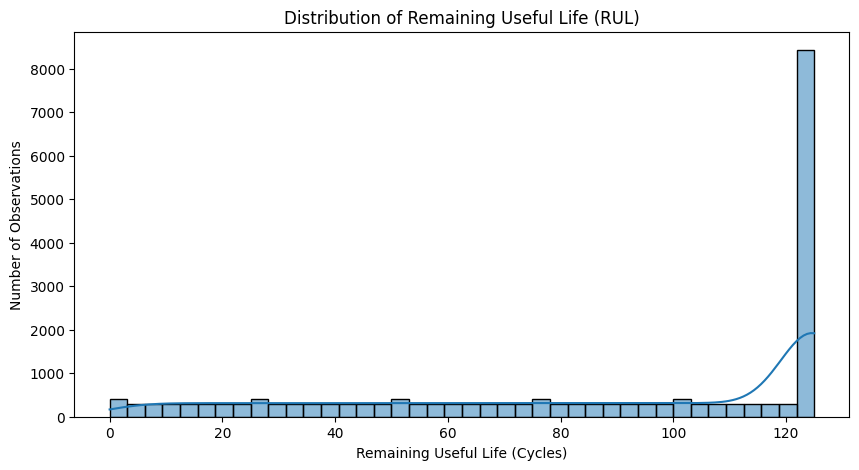

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["RUL"],
    bins=40,
    kde=True
)

plt.title("Distribution of Remaining Useful Life (RUL)")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Number of Observations")

plt.show()

In [ ]:
# List all 21 sensor columns
sensor_columns = [f"sensor_{i}" for i in range(1, 22)]

# Calculate variance of each sensor
sensor_variance = train_df[sensor_columns].var().sort_values()

print("Sensor variance:")
display(sensor_variance)

Sensor variance:


,0
sensor_19,0.000000e+00
sensor_18,0.000000e+00
sensor_16,2.422479e-28
sensor_10,2.172333e-25
sensor_5,1.152399e-23
sensor_1,4.273435e-21
sensor_6,1.929279e-06
sensor_15,1.406628e-03
sensor_8,5.038938e-03
sensor_13,5.172330e-03


In [ ]:
# Identify sensors with almost no variation
constant_sensors = sensor_variance[
    sensor_variance < 1e-10
].index.tolist()

print("Sensors with almost no variation:")
print(constant_sensors)

Sensors with almost no variation:
['sensor_19', 'sensor_18', 'sensor_16', 'sensor_10', 'sensor_5', 'sensor_1']


In [ ]:
# Keep only sensors that have meaningful variation
features = [
    sensor for sensor in sensor_columns
    if sensor not in constant_sensors
]

print("Original number of sensors:", len(sensor_columns))
print("Removed sensors:", constant_sensors)
print("Remaining sensors:", len(features))
print("\nSensors used for modelling:")
print(features)

Original number of sensors: 21
Removed sensors: ['sensor_19', 'sensor_18', 'sensor_16', 'sensor_10', 'sensor_5', 'sensor_1']
Remaining sensors: 15

Sensors used for modelling:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [ ]:
# Calculate correlation between each sensor and RUL
correlations = train_df[features + ["RUL"]].corr()["RUL"].drop("RUL")

# Sort from strongest negative to strongest positive
correlations = correlations.sort_values()

print("Correlation of sensors with RUL:")
display(correlations)

Correlation of sensors with RUL:


,RUL
sensor_11,-0.775230
sensor_4,-0.757157
sensor_15,-0.720858
sensor_17,-0.680829
sensor_2,-0.678458
sensor_3,-0.655030
sensor_8,-0.624568
sensor_13,-0.624034
sensor_9,-0.462151
sensor_14,-0.369753


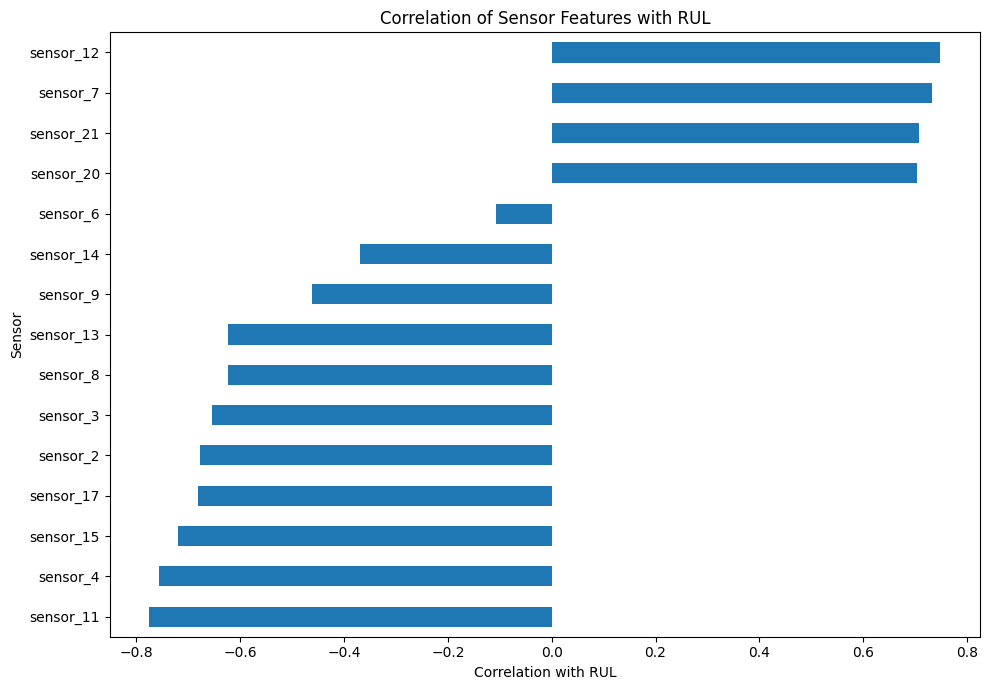

In [ ]:
plt.figure(figsize=(10, 7))

correlations.plot(kind="barh")

plt.title("Correlation of Sensor Features with RUL")
plt.xlabel("Correlation with RUL")
plt.ylabel("Sensor")

plt.tight_layout()
plt.show()

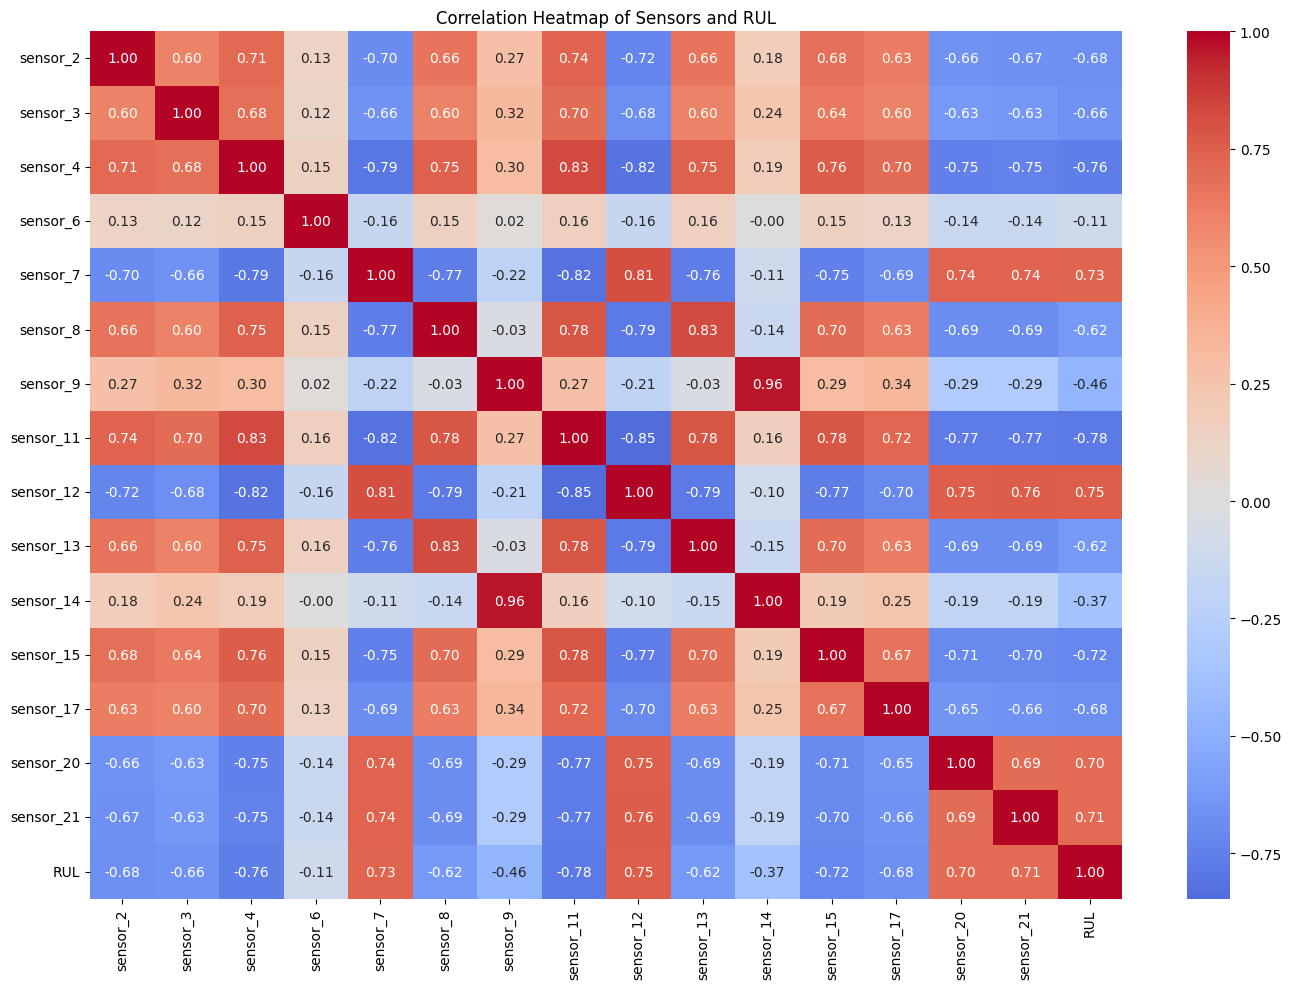

In [ ]:
plt.figure(figsize=(14, 10))

corr_matrix = train_df[features + ["RUL"]].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Sensors and RUL")
plt.tight_layout()
plt.show()

In [ ]:
top_sensors = correlations.abs().sort_values(
    ascending=False
).head(5).index.tolist()

print("Top 5 degradation-related sensors:")
print(top_sensors)

Top 5 degradation-related sensors:
['sensor_11', 'sensor_4', 'sensor_12', 'sensor_7', 'sensor_15']


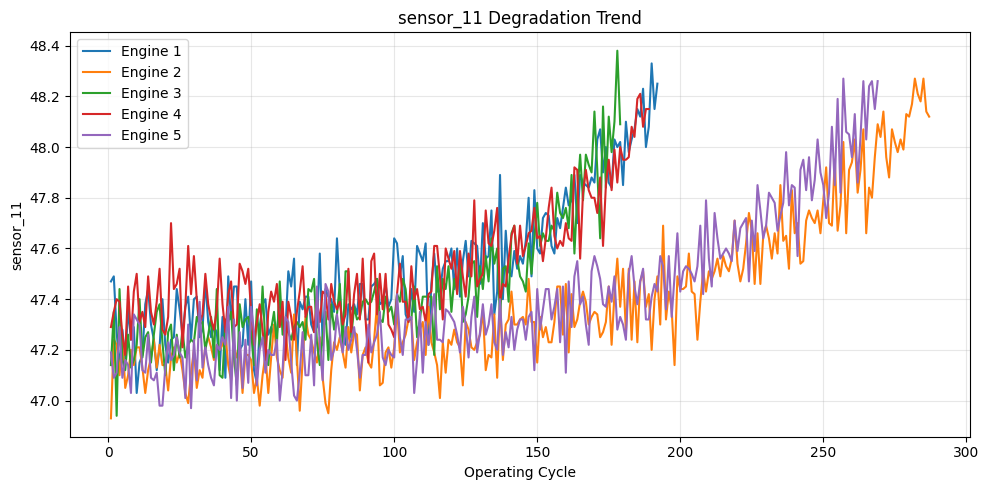

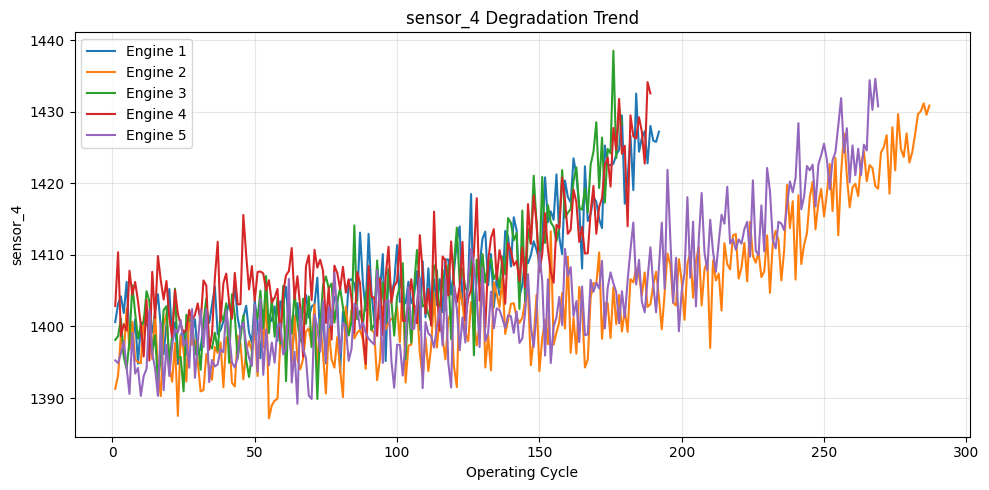

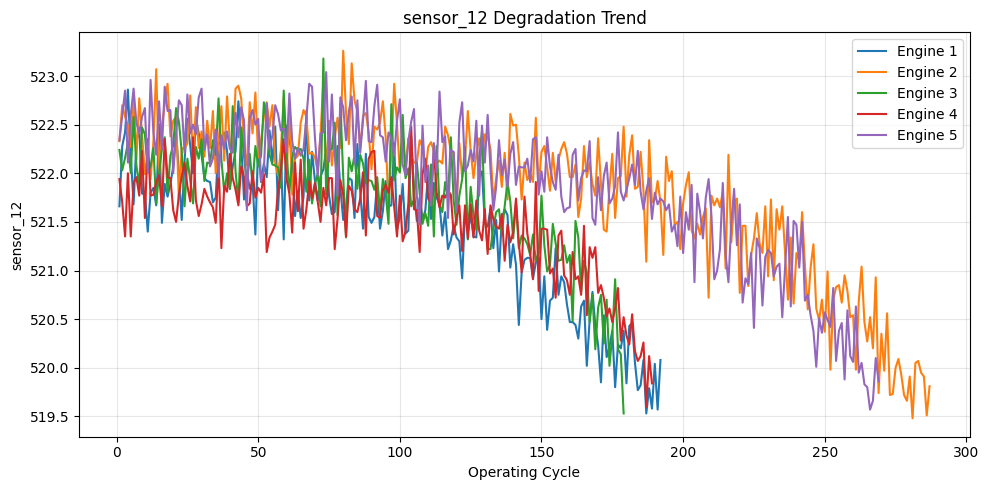

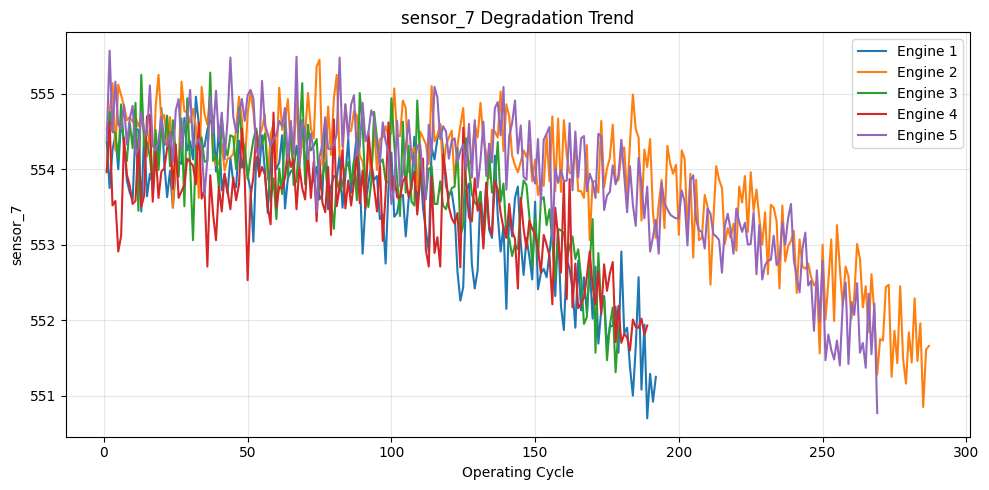

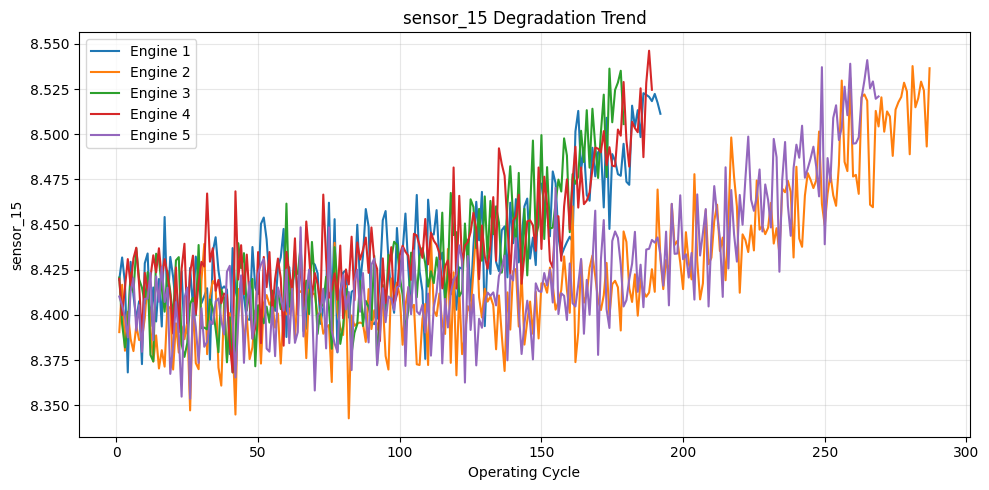

In [ ]:
# Plot degradation trends for the top 5 sensors

for sensor in top_sensors:

    plt.figure(figsize=(10, 5))

    # Plot first 5 engines for clarity
    for unit in range(1, 6):

        engine_data = train_df[train_df["unit"] == unit]

        plt.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {unit}"
        )

    plt.title(f"{sensor} Degradation Trend")
    plt.xlabel("Operating Cycle")
    plt.ylabel(sensor)
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

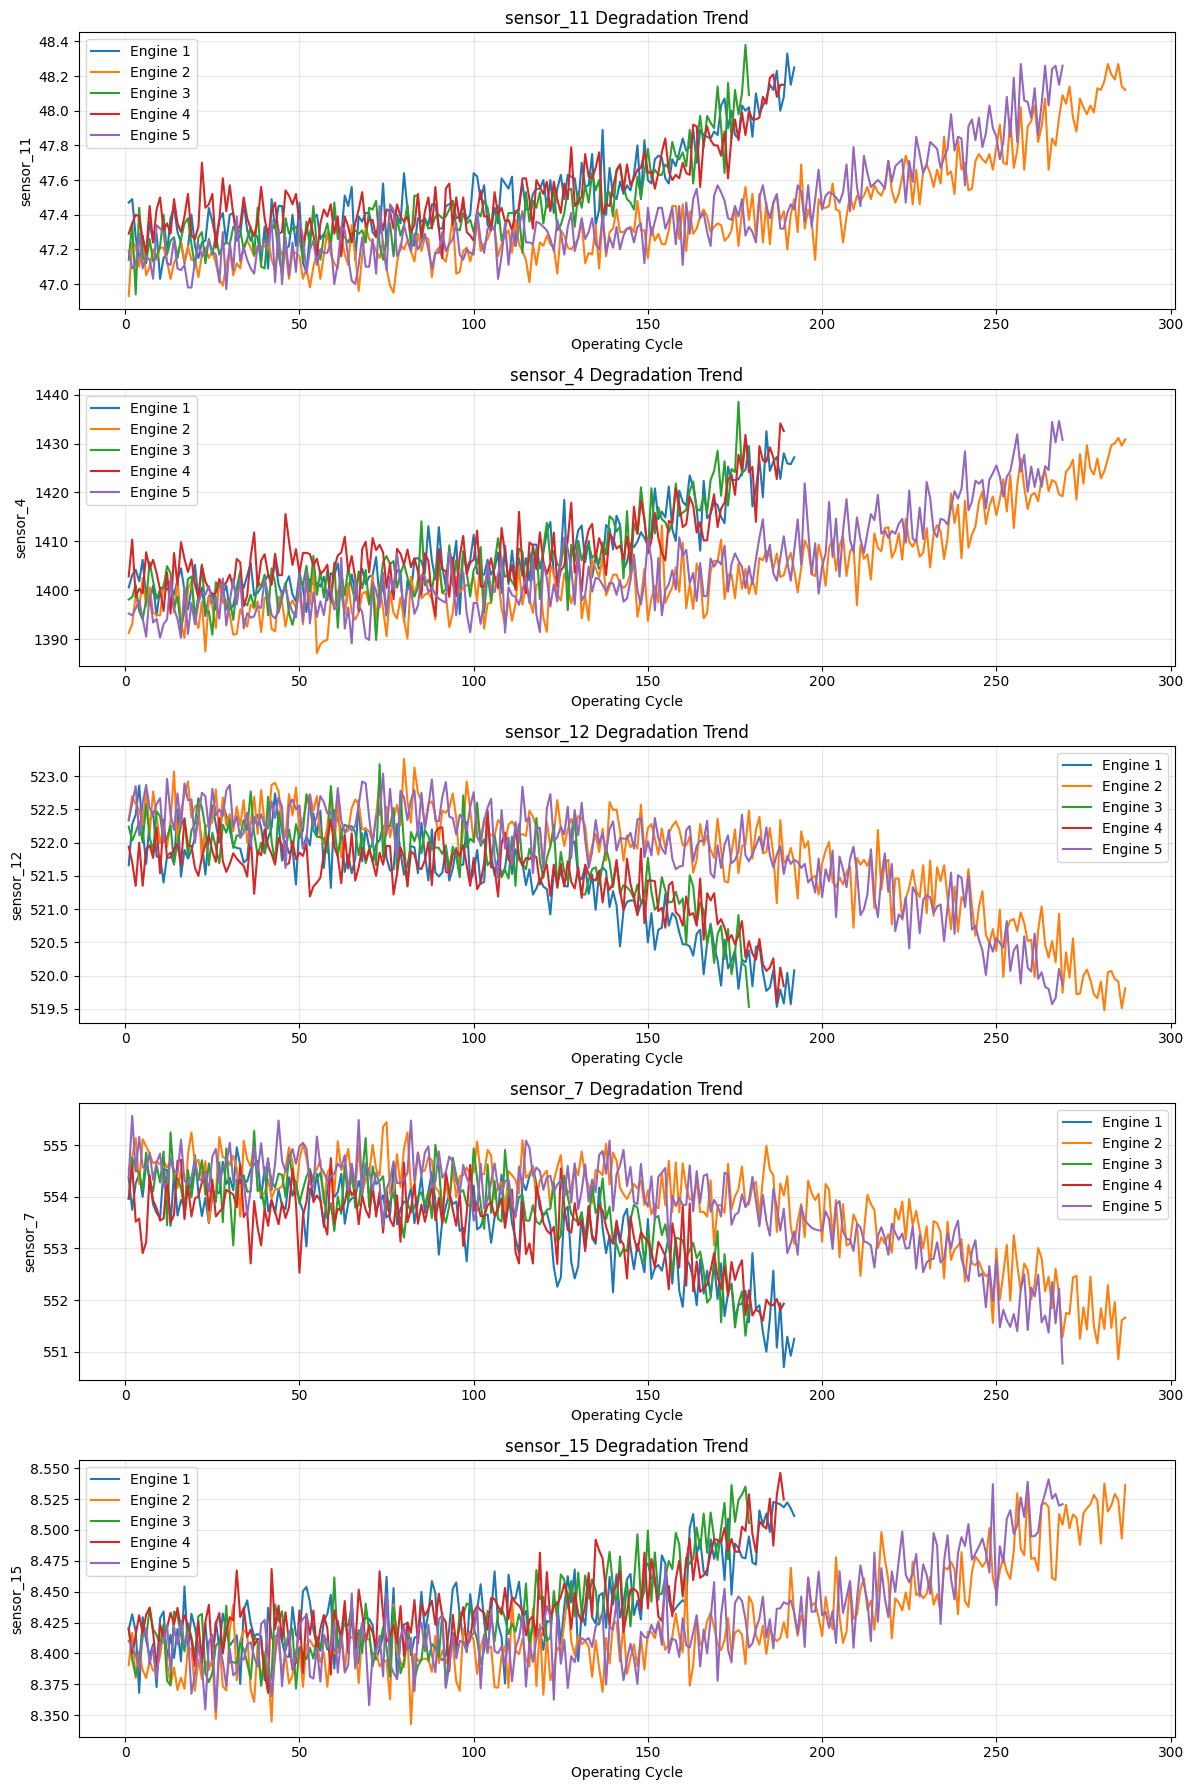

In [ ]:
fig, axes = plt.subplots(
    len(top_sensors),
    1,
    figsize=(12, 18)
)

for ax, sensor in zip(axes, top_sensors):

    for unit in range(1, 6):

        engine_data = train_df[train_df["unit"] == unit]

        ax.plot(
            engine_data["cycle"],
            engine_data[sensor],
            label=f"Engine {unit}"
        )

    ax.set_title(f"{sensor} Degradation Trend")
    ax.set_xlabel("Operating Cycle")
    ax.set_ylabel(sensor)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
# Features (input variables)
X = train_df[features]

# Target (what the model needs to predict)
y = train_df["RUL"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeatures used:")
print(features)

Feature shape: (20631, 15)
Target shape: (20631,)

Features used:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [ ]:
from sklearn.model_selection import train_test_split

# Get all unique engine IDs
units = train_df["unit"].unique()

# Split engines into training and validation groups
train_units, val_units = train_test_split(
    units,
    test_size=0.20,
    random_state=42
)

print("Total engines:", len(units))
print("Training engines:", len(train_units))
print("Validation engines:", len(val_units))

Total engines: 100
Training engines: 80
Validation engines: 20


In [ ]:
# Select complete engines for training
train_data = train_df[
    train_df["unit"].isin(train_units)
].copy()

# Select complete engines for validation
val_data = train_df[
    train_df["unit"].isin(val_units)
].copy()

# Separate features and target
X_train = train_data[features]
y_train = train_data["RUL"]

X_val = val_data[features]
y_val = val_data["RUL"]

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)

Training data: (16561, 15)
Validation data: (4070, 15)


In [ ]:
overlap = set(train_units).intersection(set(val_units))

print("Common engines between training and validation:", overlap)

Common engines between training and validation: set()


In [ ]:
print("Training feature sample:")
display(X_train.head())

print("\nTraining RUL sample:")
display(y_train.head())

Training feature sample:


,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
192,641.89,1583.84,1391.28,21.60,554.53,2388.01,9054.72,46.93,522.33,2388.06,8137.72,8.3905,391,38.94,23.4585
193,641.82,1587.05,1393.13,21.61,554.77,2387.98,9051.31,47.24,522.70,2387.98,8131.09,8.4167,392,39.06,23.4085
194,641.55,1588.32,1398.96,21.60,555.14,2388.04,9054.24,47.22,522.58,2387.99,8140.58,8.3802,391,39.11,23.4250
195,641.68,1584.15,1396.08,21.61,554.25,2387.98,9058.01,47.10,522.49,2387.93,8140.44,8.4018,391,39.13,23.5027
196,641.73,1579.03,1402.52,21.60,555.12,2388.03,9058.15,47.25,522.27,2387.94,8136.67,8.3867,390,39.18,23.4234



Training RUL sample:


,RUL
192,125.0
193,125.0
194,125.0
195,125.0
196,125.0


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict RUL on validation data
rf_pred = rf_model.predict(X_val)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_val, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
rf_r2 = r2_score(y_val, rf_pred)

print("Random Forest Results")
print("---------------------")
print(f"MAE  : {rf_mae:.4f}")
print(f"RMSE : {rf_rmse:.4f}")
print(f"R²   : {rf_r2:.4f}")

Random Forest Results
---------------------
MAE  : 12.4816
RMSE : 17.1007
R²   : 0.8320


In [ ]:
  from sklearn.ensemble import ExtraTreesRegressor

# Create Extra Trees model
et_model = ExtraTreesRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

# Train the model
et_model.fit(X_train, y_train)

# Predict RUL
et_pred = et_model.predict(X_val)

# Calculate evaluation metrics
et_mae = mean_absolute_error(y_val, et_pred)
et_rmse = np.sqrt(mean_squared_error(y_val, et_pred))
et_r2 = r2_score(y_val, et_pred)

print("Extra Trees Results")
print("-------------------")
print(f"MAE  : {et_mae:.4f}")
print(f"RMSE : {et_rmse:.4f}")
print(f"R²   : {et_r2:.4f}")

Extra Trees Results
-------------------
MAE  : 12.4261
RMSE : 16.8752
R²   : 0.8364


In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

# Create Gradient Boosting model
gb_model = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

# Predict RUL on validation data
gb_pred = gb_model.predict(X_val)

# Calculate evaluation metrics
gb_mae = mean_absolute_error(y_val, gb_pred)
gb_rmse = np.sqrt(mean_squared_error(y_val, gb_pred))
gb_r2 = r2_score(y_val, gb_pred)

print("Gradient Boosting Results")
print("-------------------------")
print(f"MAE  : {gb_mae:.4f}")
print(f"RMSE : {gb_rmse:.4f}")
print(f"R²   : {gb_r2:.4f}")

Gradient Boosting Results
-------------------------
MAE  : 12.4583
RMSE : 16.9987
R²   : 0.8340


In [ ]:
from sklearn.ensemble import VotingRegressor

# Create the Voting Ensemble
ensemble_model = VotingRegressor(
    estimators=[
        ("random_forest", rf_model),
        ("extra_trees", et_model),
        ("gradient_boosting", gb_model)
    ]
)

# Train the ensemble
ensemble_model.fit(X_train, y_train)

# Predict RUL on validation data
ensemble_pred = ensemble_model.predict(X_val)

# Calculate evaluation metrics
ensemble_mae = mean_absolute_error(y_val, ensemble_pred)
ensemble_rmse = np.sqrt(mean_squared_error(y_val, ensemble_pred))
ensemble_r2 = r2_score(y_val, ensemble_pred)

print("Voting Ensemble Results")
print("-----------------------")
print(f"MAE  : {ensemble_mae:.4f}")
print(f"RMSE : {ensemble_rmse:.4f}")
print(f"R²   : {ensemble_r2:.4f}")

Voting Ensemble Results
-----------------------
MAE  : 12.3520
RMSE : 16.8422
R²   : 0.8370


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "Voting Ensemble"
    ],
    "MAE": [
        rf_mae,
        et_mae,
        gb_mae,
        ensemble_mae
    ],
    "RMSE": [
        rf_rmse,
        et_rmse,
        gb_rmse,
        ensemble_rmse
    ],
    "R²": [
        rf_r2,
        et_r2,
        gb_r2,
        ensemble_r2
    ]
})

results.round(4)

,Model,MAE,RMSE,R²
0,Random Forest,12.4816,17.1007,0.8320
1,Extra Trees,12.4261,16.8752,0.8364
2,Gradient Boosting,12.4583,16.9987,0.8340
3,Voting Ensemble,12.3520,16.8422,0.8370


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting",
        "Voting Ensemble"
    ],
    "MAE": [
        rf_mae,
        et_mae,
        gb_mae,
        ensemble_mae
    ],
    "RMSE": [
        rf_rmse,
        et_rmse,
        gb_rmse,
        ensemble_rmse
    ],
    "R²": [
        rf_r2,
        et_r2,
        gb_r2,
        ensemble_r2
    ]
})

display(results.round(4))

,Model,MAE,RMSE,R²
0,Random Forest,12.4816,17.1007,0.8320
1,Extra Trees,12.4261,16.8752,0.8364
2,Gradient Boosting,12.4583,16.9987,0.8340
3,Voting Ensemble,12.3520,16.8422,0.8370


<Figure size 1200x600 with 0 Axes>

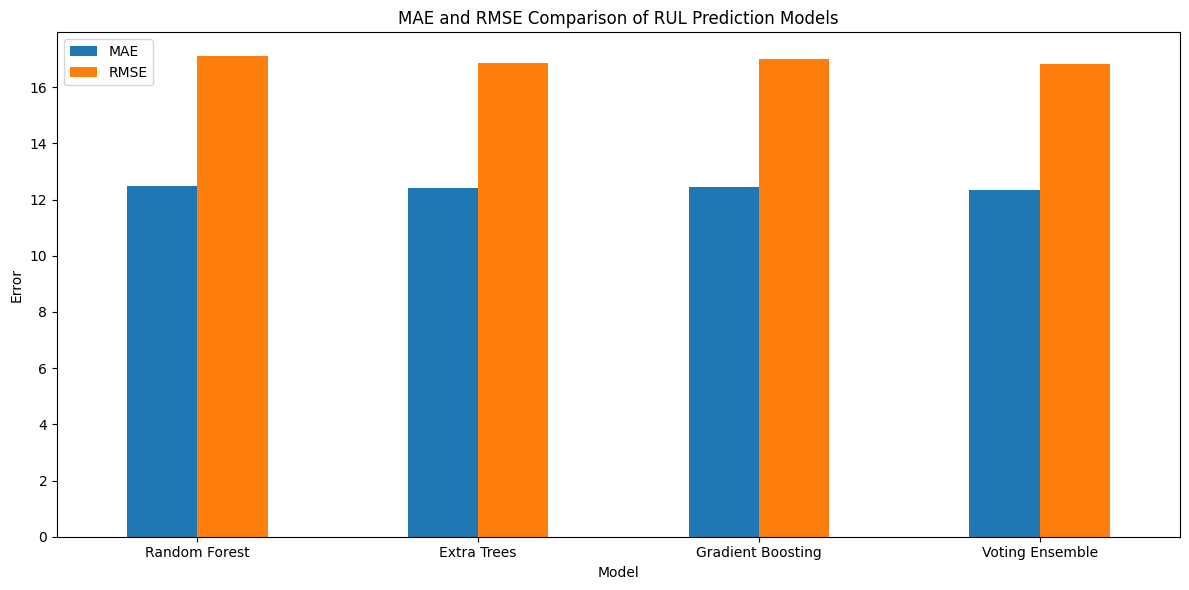

In [ ]:
plt.figure(figsize=(12, 6))

results.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("MAE and RMSE Comparison of RUL Prediction Models")
plt.xlabel("Model")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
feature_importance = pd.DataFrame({
    "Sensor": features,
    "Importance": et_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance)

,Sensor,Importance
7,sensor_11,0.190707
2,sensor_4,0.143845
8,sensor_12,0.119773
6,sensor_9,0.078002
4,sensor_7,0.077902
10,sensor_14,0.063303
11,sensor_15,0.060464
14,sensor_21,0.059070
13,sensor_20,0.048351
0,sensor_2,0.040703


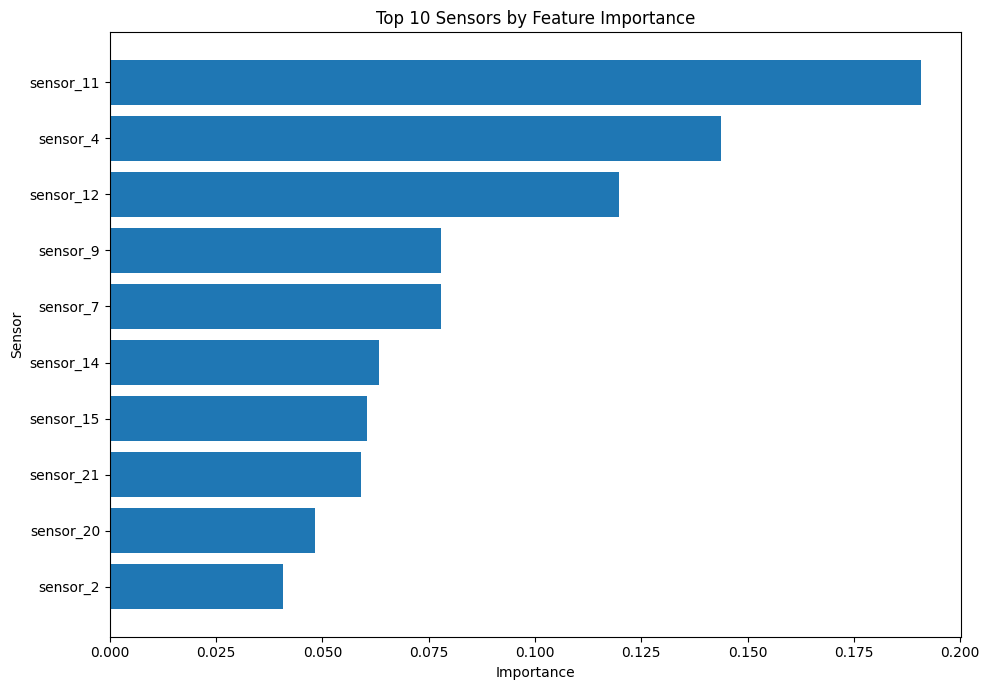

In [ ]:
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(10)

plt.barh(
    top_features["Sensor"][::-1],
    top_features["Importance"][::-1]
)

plt.title("Top 10 Sensors by Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Sensor")

plt.tight_layout()
plt.show()

In [ ]:
# Select the last available cycle for each test engine
test_last_cycle = test_df.groupby("unit")["cycle"].max()

# Keep only the final observation of each engine
test_final = test_df.loc[
    test_df.groupby("unit")["cycle"].idxmax()
].copy()

# Add the official RUL values
test_final["RUL"] = rul_df["RUL"].values

print("Final test engines:", len(test_final))
print("Test data shape:", test_final.shape)

display(test_final.head())

Final test engines: 100
Test data shape: (100, 27)


,unit,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552,112
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618,98
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740,69
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581,82
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117,91


In [ ]:
X_test = test_final[features]
y_test = test_final["RUL"]

print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Test features shape: (100, 15)
Test target shape: (100,)


In [ ]:
# Predict RUL using the trained Voting Ensemble
test_pred = ensemble_model.predict(X_test)

# Calculate official test metrics
test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred)

print("Official FD001 Test Results")
print("===========================")
print(f"MAE  : {test_mae:.4f}")
print(f"RMSE : {test_rmse:.4f}")
print(f"R²   : {test_r2:.4f}")

Official FD001 Test Results
MAE  : 12.6120
RMSE : 17.7962
R²   : 0.8166


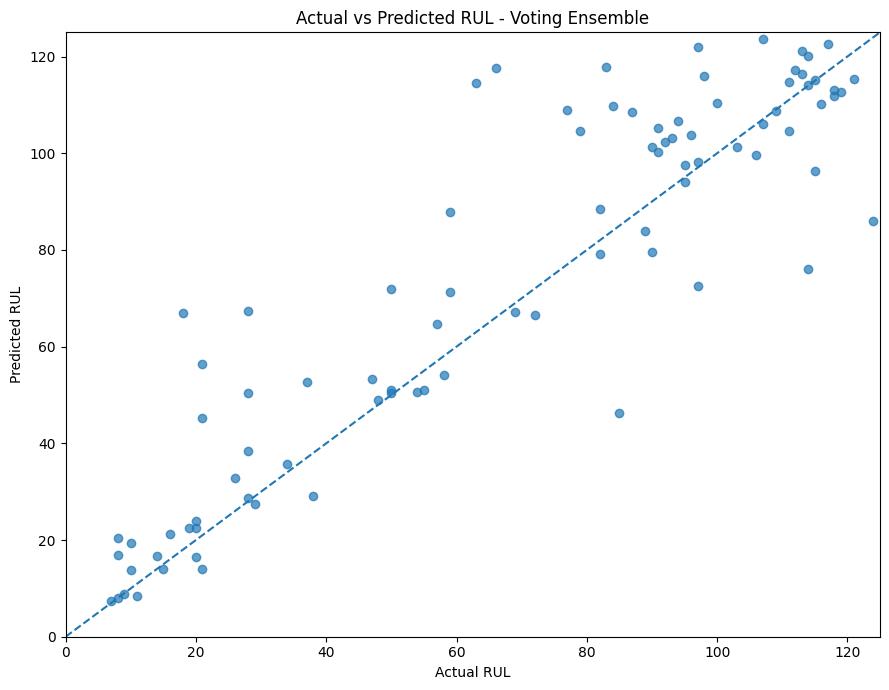

In [ ]:
plt.figure(figsize=(9, 7))

plt.scatter(
    y_test,
    test_pred,
    alpha=0.7
)

# Perfect prediction line
plt.plot(
    [0, 125],
    [0, 125],
    linestyle="--"
)

plt.xlabel("Actual RUL")
plt.ylabel("Predicted RUL")
plt.title("Actual vs Predicted RUL - Voting Ensemble")

plt.xlim(0, 125)
plt.ylim(0, 125)

plt.tight_layout()
plt.show()

In [ ]:
prediction_results = pd.DataFrame({
    "Engine": test_final["unit"].values,
    "Actual_RUL": y_test.values,
    "Predicted_RUL": test_pred
})

prediction_results["Absolute_Error"] = abs(
    prediction_results["Actual_RUL"] -
    prediction_results["Predicted_RUL"]
)

display(prediction_results.head(10))

,Engine,Actual_RUL,Predicted_RUL,Absolute_Error
0,1,112,117.187467,5.187467
1,2,98,116.069305,18.069305
2,3,69,67.120056,1.879944
3,4,82,88.549377,6.549377
4,5,91,100.207483,9.207483
5,6,93,103.100467,10.100467
6,7,91,105.242571,14.242571
7,8,95,97.465930,2.465930
8,9,111,104.669424,6.330576
9,10,96,103.776868,7.776868


In [ ]:
prediction_results.round(2)

,Engine,Actual_RUL,Predicted_RUL,Absolute_Error
0,1,112,117.19,5.19
1,2,98,116.07,18.07
2,3,69,67.12,1.88
3,4,82,88.55,6.55
4,5,91,100.21,9.21
...,...,...,...,...
95,96,137,122.04,14.96
96,97,82,79.19,2.81
97,98,59,87.81,28.81
98,99,117,122.64,5.64


In [ ]:
import joblib

# Save the trained Voting Ensemble
joblib.dump(
    ensemble_model,
    "rul_ensemble_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [ ]:
import json

# Save the feature names used by the model
with open("features.json", "w") as f:
    json.dump(features, f, indent=4)

print("Feature list saved successfully!")
print(features)

Feature list saved successfully!
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [ ]:
model_info = {
    "model": "Voting Ensemble",
    "base_models": [
        "Random Forest",
        "Extra Trees",
        "Gradient Boosting"
    ],
    "dataset": "NASA C-MAPSS FD001",
    "max_rul": 125,
    "features": features,
    "test_metrics": {
        "MAE": round(test_mae, 4),
        "RMSE": round(test_rmse, 4),
        "R2": round(test_r2, 4)
    }
}

with open("model_info.json", "w") as f:
    json.dump(model_info, f, indent=4)

print("Model information saved!")

Model information saved!


In [ ]:
from google.colab import files

files.download("rul_ensemble_model.pkl")
files.download("features.json")
files.download("model_info.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>